# Shared hyperparameter selection with Optuna

This notebook is independent of `models.ipynb`. It predeclares development
and evaluation people, tunes shared kNN/OCSVM settings using labeled development
probes, freezes selections, then evaluates independently enrolled evaluation
users. Each personal detector and its preprocessing see only that user's
first five genuine attempts. This is genuine-only personal enrollment with
population-supervised parameter selection.

KMT has already been explored in this project. A new split improves selection
discipline; it does not create an independent dataset or cross-session evidence.


In [1]:
import os
from pathlib import Path
import optuna
import pandas as pd
import matplotlib.pyplot as plt
from behavioral_ml import evaluation, experiment, tuning
from behavioral_ml.etl import load_data, infer_typist_candidates
from behavioral_ml.features import build_feature_sets

optuna.logging.set_verbosity(optuna.logging.WARNING)
data_dir = Path(os.environ.get("KMT_DATA_DIR", "../data/raw_kmt_dataset"))
mouse_events, key_events = load_data(data_dir)
feature_sets = build_feature_sets(mouse_events, key_events)
typist_candidates = infer_typist_candidates(key_events)
pd.DataFrame({name: {"attempts": len(frame), "features": frame.shape[1]}
              for name, frame in feature_sets.items()}).T


/Volumes/Workspace/01_Projects/behavioral-ml/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/10/28 16:28:46 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Volumes/Workspace/01_Projects/behavioral-ml/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


,attempts,features
keys,1760,18
mouse,1760,21
keys_mouse,1760,39


## Declare the protocol and inspect coverage

The seeded 70/30 identity split is fixed before optimization. A probe is retained
only if its claimed owner and **every** plausible typist are within its partition;
unknown and cross-partition attempts are excluded. Person separation remains
conditional on the one-hour timestamp-attribution assumption. Every method and
feature set receives identical retained probe identities. Users without retained
impostors have undefined per-user AUC/EER and are omitted from those means.

The search budget is at most 30 trials per method/feature set. kNN exhausts its
24 configurations; OCSVM uses seeded TPE. Enrollment size and preprocessing are
fixed. Trial order is sequential; pruning is disabled for these short fits.


In [2]:
OUTPUT_DIR = Path(os.environ.get("KMT_TUNING_DIR", "../artifacts/tuning"))
N_ENROLL = 5
N_TRIALS = 30
SEED = 42
EVALUATION_FRACTION = 0.3
DETECTORS = ("knn", "ocsvm")

split, split_audit = tuning.make_identity_split(
    feature_sets["keys"], typist_candidates, n_enroll=N_ENROLL,
    evaluation_fraction=EVALUATION_FRACTION, random_state=SEED)
display(pd.DataFrame(split["coverage"]).T)
split_audit.groupby(["partition", "role", "reason"]).size().rename("attempts")


,n_candidate_probes,n_probes,n_genuine,n_impostor,n_users_with_both_classes,n_excluded_probes
development,915,672,305,367,61,243
evaluation,405,175,135,40,25,230


partition    role        reason            
development  enrollment  genuine_enrollment    305
             probe       cross_split_typist    243
                         retained              672
evaluation   enrollment  genuine_enrollment    135
             probe       cross_split_typist    230
                         retained              175
Name: attempts, dtype: int64

## Optimize development performance, then freeze

One study per detector × feature set maximizes mean per-user development ROC
AUC. Both parameter and feature selection use development performance only.
All six configurations and the overall development-selected winner are written
to `selection.json` before evaluation scoring begins. The best development
objective is selection-biased and is not a final generalization estimate.

SQLite retains completed trials after interruption. A completed directory can
be rerun using its frozen choices; changing inputs, code, settings, or budget
requires another directory. Restarting an unfinished TPE study retains previous
trials but can change subsequent proposals because its sampler RNG restarts.


In [3]:
evaluation_scores, selection = tuning.run_tuning(
    feature_sets, typist_candidates, OUTPUT_DIR, n_enroll=N_ENROLL,
    n_trials=N_TRIALS, evaluation_fraction=EVALUATION_FRACTION,
    random_state=SEED, detector_names=DETECTORS, data_dir=data_dir)
choices = pd.DataFrame(selection["configurations"]).T
print("Selected using development AUC:", selection["selected_experiment"])
choices[["development_mean_user_auc", "params", "best_trial"]]


2026/10/28 16:29:43 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/28 16:29:43 INFO mlflow.store.db.utils: Updating database tables


Selected using development AUC: p2.knn.keys


,development_mean_user_auc,params,best_trial
p2.knn.keys,0.95055,"{'n_neighbors': 2, 'method': 'mean', 'metric':...",5
p2.knn.mouse,0.824067,"{'n_neighbors': 3, 'method': 'median', 'metric...",3
p2.knn.keys_mouse,0.91952,"{'n_neighbors': 3, 'method': 'largest', 'metri...",10
p2.ocsvm.keys,0.944723,"{'nu': 0.1097809185294969, 'gamma': 0.02702584...",29
p2.ocsvm.mouse,0.812758,"{'nu': 0.06942615855268755, 'gamma': 0.0106757...",28
p2.ocsvm.keys_mouse,0.90999,"{'nu': 0.053101877874091326, 'gamma': 0.022736...",21


## Evaluation with frozen configurations

These results use evaluation probe labels only for reporting. Do not choose
another winner from this table or append trials using its results. Scores from
independent personal models are not calibrated to a common probability scale.
EER and FRR-at-FAR remain descriptive; a deployable threshold would require
separate calibration and a further untouched test. Sparse retained impostors
limit the resolution of low-FAR and per-user statistics.


In [4]:
evaluation_results = experiment.results_table(evaluation_scores)
evaluation_results


,n_probes,n_genuine,n_impostor,n_users_with_both_classes,pooled_auc,pooled_eer,per_user_auc_mean,per_user_auc_median,pooled_frr_at_far_0.01,per_user_eer_mean,per_user_eer_median,per_user_eer_iqr
experiment,,,,,,,,,,,,
p2.knn.keys,175.0,135.0,40.0,25.0,0.907037,0.176389,0.978667,1.0,0.807407,0.018667,0.0,0.000000
p2.knn.mouse,175.0,135.0,40.0,25.0,0.766111,0.349074,0.812000,0.9,0.814815,0.166667,0.1,0.200000
p2.knn.keys_mouse,175.0,135.0,40.0,25.0,0.922222,0.149074,0.938667,1.0,0.600000,0.049333,0.0,0.000000
p2.ocsvm.keys,175.0,135.0,40.0,25.0,0.920741,0.149074,0.970667,1.0,0.807407,0.022667,0.0,0.000000
p2.ocsvm.mouse,175.0,135.0,40.0,25.0,0.759537,0.321759,0.817333,0.9,0.918519,0.190667,0.1,0.266667
p2.ocsvm.keys_mouse,175.0,135.0,40.0,25.0,0.848519,0.223611,0.917333,1.0,0.525926,0.085333,0.0,0.100000


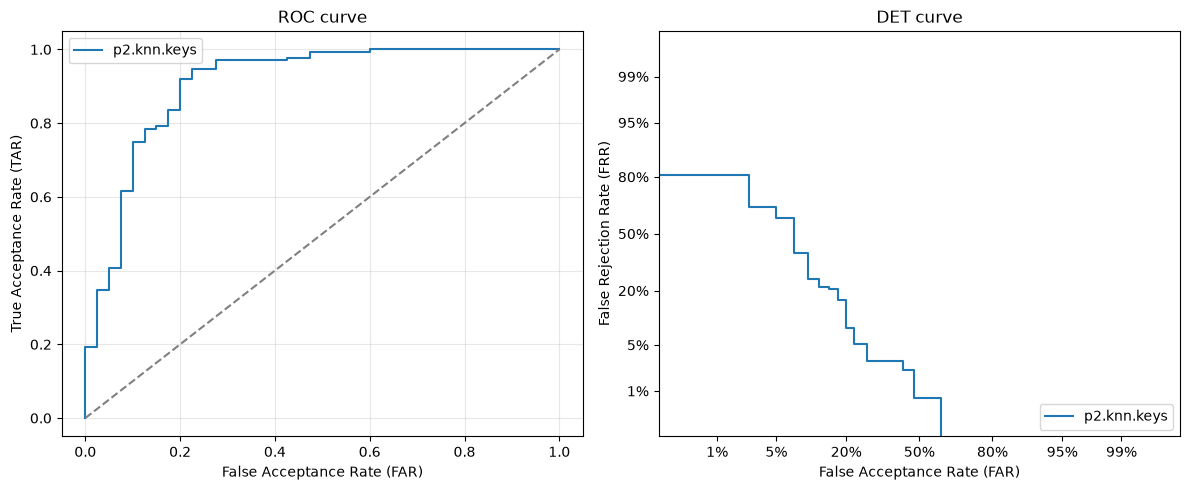

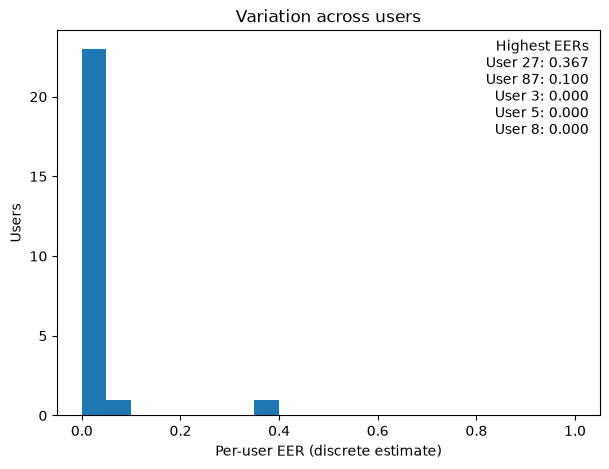

In [5]:
selected_name = selection["selected_experiment"]
selected_scores = evaluation_scores[selected_name]
report = evaluation.verification_report(
    selected_scores.index.get_level_values("Is Genuine"), selected_scores)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
evaluation.plot_roc_curve(report, ax=axes[0], label=selected_name)
evaluation.plot_det_curve(report, ax=axes[1], label=selected_name)
plt.tight_layout()
plt.show()
evaluation.plot_per_user_eer(evaluation.per_user_metrics(selected_scores))
plt.show()


## Saved evidence

`OUTPUT_DIR` contains the identity manifest, attempt-level exclusion audit,
input/source/version contract, Optuna SQLite studies, trial tables, and frozen
selection. `evaluation/` contains indexed scores and pooled/per-user reports.
`models/` contains one joblib mapping of claimed user IDs to enrollment-fitted
pipelines per configuration. MLflow logs development trials and evaluation as
separate phases, including plots, configuration, provenance, and model bundles.

Single-session collection, practice/content asymmetry, uncertain attacker IDs,
and the small sample still limit the conclusions. The dataset is KMT,
Nnamoko et al. (2022), Mendeley Data v1, CC BY 4.0; see the README references.
